In [1]:
import numpy as np
import  pandas as pd
import librosa, librosa.display
import matplotlib.pyplot as plt
import os
import torch, torchaudio
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import IPython.display as ipd
import random
import seaborn as sns
from sklearn.model_selection import StratifiedShuffleSplit

# Data Loading Pipeline

In [2]:
BASE = "/kaggle/input/competitions/birdclef-2025"  # <-- CHANGE THIS to what FOUND printed
# example: BASE = "/kaggle/input/birdclef-2025/birdclef-2025" if needed

train = pd.read_csv(f"{BASE}/train.csv")
taxonomy = pd.read_csv(f"{BASE}/taxonomy.csv")
print(BASE, train.shape)

/kaggle/input/competitions/birdclef-2025 (28564, 13)


In [3]:
taxonomy.head()

,primary_label,inat_taxon_id,scientific_name,common_name,class_name
0,1139490,1139490,Ragoniella pulchella,Ragoniella pulchella,Insecta
1,1192948,1192948,Oxyprora surinamensis,Oxyprora surinamensis,Insecta
2,1194042,1194042,Copiphora colombiae,Copiphora colombiae,Insecta
3,126247,126247,Leptodactylus insularum,Spotted Foam-nest Frog,Amphibia
4,1346504,1346504,Neoconocephalus brachypterus,Neoconocephalus brachypterus,Insecta


In [4]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [5]:
sample_df=train.sample(frac=0.3,random_state=42)
sample_df.shape

(8569, 13)

In [6]:
labels=sorted(train['primary_label'].unique())
label2idx={l:i for i,l in enumerate(labels)}
idx2label={i:l for l,i in label2idx.items()}

In [7]:
class CFG:
    SR=32000
    DURATION=5
    N_MELS=128
    BATCH=32

In [8]:
class BirdDataset(Dataset):
    def __init__(self, df):
        self.df = df
        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=CFG.SR, n_mels=CFG.N_MELS, f_min=50, f_max=14000, n_fft=1024, hop_length=512
        )
        self.db = torchaudio.transforms.AmplitudeToDB()

    def __len__(self):
        return len(self.df)

    def __getitem__(self,idx):
        row=self.df.iloc[idx]
        path = os.path.join(BASE, "train_audio", row['filename'])
        wav,sr=torchaudio.load(path)
        wav=wav.mean(dim=0)
        if sr != CFG.SR:
            resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=CFG.SR)
            wav = resampler(wav)
        target = CFG.SR * CFG.DURATION
        if len(wav) > target:
            start = torch.randint(0, len(wav)-target, (1,)).item()
            wav = wav[start:start+target]
        else:
            wav = F.pad(wav, (0, target - len(wav)))
            
        mel = self.mel(wav)
        mel = self.db(mel)
        mel = (mel - mel.mean()) / (mel.std() + 1e-6)
        
        label = label2idx[row['primary_label']]
        return mel, label


In [9]:
splitter=StratifiedShuffleSplit(n_splits=1,test_size=0.2,random_state=42)

In [10]:
counts=sample_df['primary_label'].value_counts()
counts

primary_label
grekis     301
compau     256
trokin     206
roahaw     190
banana     179
          ... 
1192948      1
66893        1
868458       1
134933       1
65336        1
Name: count, Length: 195, dtype: int64

In [11]:
rare_classes=counts[counts==1].index
rare_classes.shape

(14,)

In [12]:
sample_df = sample_df[~sample_df['primary_label'].isin(rare_classes)].reset_index(drop=True)

In [13]:
sample_df.shape

(8555, 13)

In [14]:
train_idx, val_idx = next(splitter.split(sample_df, sample_df['primary_label']))

In [15]:
train_df = sample_df.iloc[train_idx].reset_index(drop=True)
val_df = sample_df.iloc[val_idx].reset_index(drop=True)

print(f"Train size: {len(train_df)} | Val size: {len(val_df)}")

Train size: 6844 | Val size: 1711


In [16]:
train_dataset=BirdDataset(train_df)
val_dataset=BirdDataset(val_df)

In [17]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

In [18]:
mels, labs = next(iter(train_loader))
print("Batch shape:", mels.shape)       
print("Labels shape:", labs.shape)

Batch shape: torch.Size([32, 128, 313])
Labels shape: torch.Size([32])


# Buidling Hybird Model

In [19]:
import torch.nn as nn
import timm

class HybridBirdModel(nn.Module):
    def __init__(self, num_classes=206):
        super().__init__()
        
        # Step A: Backbone (CNN feature extractor)
        self.backbone = timm.create_model(
            'tf_efficientnet_b0', 
            pretrained=True, 
            in_chans=1, 
            num_classes=0, 
            global_pool=''
        )
        
        # Step C: Transformer (Processes the sequence of patches)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=1280, 
            nhead=8, 
            dropout=0.1, 
            batch_first=True # Crucial: PyTorch expects [Batch, Seq, Features]
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        
        # Step D: Final Classifier
        self.classifier = nn.Linear(1280, num_classes)

    def forward(self, x):
        # print(f"Input: {x.shape}")
        features = self.backbone(x)
        # print(f"After CNN: {features.shape}")
        
        features = features.permute(0, 2, 3, 1)
        # print(f"After Permute: {features.shape}")
        
        features = features.flatten(1, 2)
        # print(f"After Flatten: {features.shape}")
        
        trans_out = self.transformer(features)
        # print(f"After Transformer: {trans_out.shape}")
        
        pooled = trans_out.mean(dim=1)
        # print(f"After Pooling: {pooled.shape}")
        
        logits = self.classifier(pooled)
        # print(f"After Classifier: {logits.shape}")
        return logits

In [20]:
model = HybridBirdModel(num_classes=206).to(device)
dummy = torch.randn(2, 1, 128, 313).to(device)

with torch.no_grad():
    out = model(dummy)

print(out.shape) # MUST PRINT: torch.Size([2, 206])

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

torch.Size([2, 206])


# The Training Loop

In [21]:
import time
import torch.optim as optim

# --- 1. INSTANTIATE THE HYBRID MODEL ---
# Make sure HybridBirdModel class is already defined in a previous cell!
model = HybridBirdModel(num_classes=206).to(device)

# --- 2. SETUP OPTIMIZER & SCHEDULER (The "Gentler Touch") ---
criterion = torch.nn.CrossEntropyLoss()

# Notice the lr=5e-4 
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-2)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

try:
    scaler = torch.amp.GradScaler('cuda')
except AttributeError:
    scaler = torch.cuda.amp.GradScaler()

# --- 3. HISTORY DICTIONARY FOR PLOTTING ---
history = {'train_loss': [],'val_loss': []}
epochs = 10

# --- 4. THE TRAINING LOOP ---
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    start_time = time.time()
    
    for batch_idx, (mels, labs) in enumerate(train_loader):
        
        # Move data to GPU and add channel dim
        mels = mels.to(device).unsqueeze(1)
        labs = labs.to(device)
        
        # Zero gradients
        optimizer.zero_grad()
        
        # Forward pass with Mixed Precision
        with torch.cuda.amp.autocast():
            outputs = model(mels)
            loss = criterion(outputs, labs)
            
        # Backward pass with Scaler
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        # Track loss
        running_loss += loss.item()
        
        if (batch_idx + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{epochs}] | Batch [{batch_idx+1}/{len(train_loader)}] | Loss: {loss.item():.4f}")
            
    # Step the scheduler ONCE per epoch
    scheduler.step()
    
    # Calculate average loss for the epoch
    avg_train_loss = running_loss / len(train_loader)
    history['train_loss'].append(avg_train_loss) # <--- SAVE FOR PLOTTING
    
    end_time = time.time()
    print(f"=== Epoch {epoch+1} Complete | Avg Train Loss: {avg_train_loss:.4f} | Time: {end_time - start_time:.1f}s ===")
    print("-" * 50)

/tmp/ipykernel_22/1005546130.py:40: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [1/10] | Batch [10/214] | Loss: 5.0931
Epoch [1/10] | Batch [20/214] | Loss: 4.9437
Epoch [1/10] | Batch [30/214] | Loss: 4.9964
Epoch [1/10] | Batch [40/214] | Loss: 4.6841
Epoch [1/10] | Batch [50/214] | Loss: 4.7604
Epoch [1/10] | Batch [60/214] | Loss: 4.2602
Epoch [1/10] | Batch [70/214] | Loss: 4.1766
Epoch [1/10] | Batch [80/214] | Loss: 4.0001
Epoch [1/10] | Batch [90/214] | Loss: 4.6132
Epoch [1/10] | Batch [100/214] | Loss: 4.3317
Epoch [1/10] | Batch [110/214] | Loss: 3.9612
Epoch [1/10] | Batch [120/214] | Loss: 3.8310
Epoch [1/10] | Batch [130/214] | Loss: 4.2272
Epoch [1/10] | Batch [140/214] | Loss: 3.7420
Epoch [1/10] | Batch [150/214] | Loss: 3.7515
Epoch [1/10] | Batch [160/214] | Loss: 3.7807
Epoch [1/10] | Batch [170/214] | Loss: 3.7366
Epoch [1/10] | Batch [180/214] | Loss: 3.5397
Epoch [1/10] | Batch [190/214] | Loss: 3.6099
Epoch [1/10] | Batch [200/214] | Loss: 3.2517
Epoch [1/10] | Batch [210/214] | Loss: 3.8278
=== Epoch 1 Complete | Avg Train Loss: 4.11

# evaluation

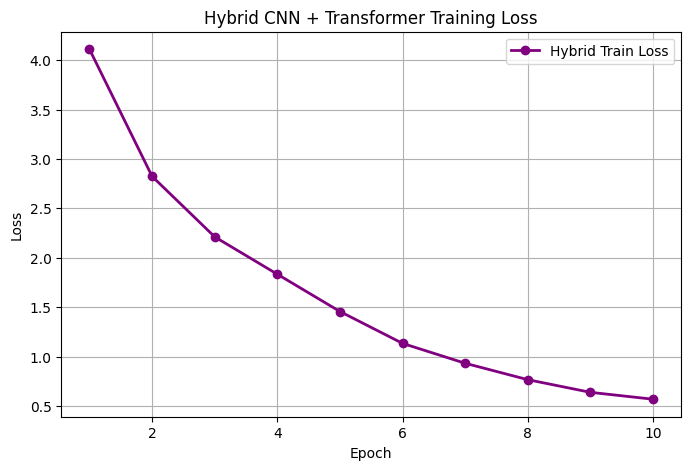

✅ Model saved as 'hybrid_efficientnet_transformer2.pth'

Running validation...


/tmp/ipykernel_22/3749022966.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


🏆 Hybrid Validation Accuracy: 56.28%
Correct predictions: 963 / 1711


In [22]:
import matplotlib.pyplot as plt

# 1. Plot the Hybrid Training Loss
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), history['train_loss'], marker='o', color='purple', linewidth=2, label='Hybrid Train Loss')
plt.title('Hybrid CNN + Transformer Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.show()

# 2. Save the model weights
torch.save(model.state_dict(), 'hybrid_efficientnet_transformer2.pth')
print("✅ Model saved as 'hybrid_efficientnet_transformer2.pth'\n")

# 3. Run Validation to check accuracy
model.eval()
correct = 0
total = 0

print("Running validation...")
with torch.no_grad():
    for mels, labs in val_loader:
        mels = mels.to(device).unsqueeze(1) # [B, 1, 128, 313]
        labs = labs.to(device)
        
        with torch.cuda.amp.autocast():
            outputs = model(mels)
            
        preds = outputs.argmax(dim=1)
        correct += (preds == labs).sum().item()
        total += labs.size(0)

val_acc = correct / total
print(f"🏆 Hybrid Validation Accuracy: {val_acc * 100:.2f}%")
print(f"Correct predictions: {correct} / {total}")

# Model Evaluation Part

In [23]:
model = HybridBirdModel()

# 1. Overall model
# print(model)

# 2. CNN architecture
# print(model.backbone)

# 3. Transformer architecture
print(model.transformer)

# 4. Classifier
print(model.classifier)

TransformerEncoder(
  (layers): ModuleList(
    (0): TransformerEncoderLayer(
      (self_attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=1280, out_features=1280, bias=True)
      )
      (linear1): Linear(in_features=1280, out_features=2048, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (linear2): Linear(in_features=2048, out_features=1280, bias=True)
      (norm1): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
      (dropout1): Dropout(p=0.1, inplace=False)
      (dropout2): Dropout(p=0.1, inplace=False)
    )
  )
)
Linear(in_features=1280, out_features=206, bias=True)


In [24]:
for name, parameter in model.named_parameters():
    print(name, parameter.shape, parameter.numel())

backbone.conv_stem.weight torch.Size([32, 1, 3, 3]) 288
backbone.bn1.weight torch.Size([32]) 32
backbone.bn1.bias torch.Size([32]) 32
backbone.blocks.0.0.conv_dw.weight torch.Size([32, 1, 3, 3]) 288
backbone.blocks.0.0.bn1.weight torch.Size([32]) 32
backbone.blocks.0.0.bn1.bias torch.Size([32]) 32
backbone.blocks.0.0.se.conv_reduce.weight torch.Size([8, 32, 1, 1]) 256
backbone.blocks.0.0.se.conv_reduce.bias torch.Size([8]) 8
backbone.blocks.0.0.se.conv_expand.weight torch.Size([32, 8, 1, 1]) 256
backbone.blocks.0.0.se.conv_expand.bias torch.Size([32]) 32
backbone.blocks.0.0.conv_pw.weight torch.Size([16, 32, 1, 1]) 512
backbone.blocks.0.0.bn2.weight torch.Size([16]) 16
backbone.blocks.0.0.bn2.bias torch.Size([16]) 16
backbone.blocks.1.0.conv_pw.weight torch.Size([96, 16, 1, 1]) 1536
backbone.blocks.1.0.bn1.weight torch.Size([96]) 96
backbone.blocks.1.0.bn1.bias torch.Size([96]) 96
backbone.blocks.1.0.conv_dw.weight torch.Size([96, 1, 3, 3]) 864
backbone.blocks.1.0.bn2.weight torch.Size

In [25]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total:", total_params)
print("Trainable:", trainable_params)

Total: 16080906
Trainable: 16080906


In [26]:
def inspect_layer(name):
    def hook(module, inputs, output):
        print(name, output.shape)

    return hook

model.backbone.register_forward_hook(
    inspect_layer("EfficientNet output")
)

model.transformer.register_forward_hook(
    inspect_layer("Transformer output")
)

In [27]:

from torchinfo import summary
import torch

# Initialize your model
model = HybridBirdModel(num_classes=206)

# Create a dummy spectrogram
# B=1, Channels=1, Height=128, Width=313
dummy_input = torch.randn(1, 1, 128, 313)

# Print model summary
summary(
    model,
    input_data=dummy_input,
    col_names=[
        "input_size",
        "output_size",
        "num_params",
        "trainable"
    ],
    depth=4,
    verbose=1
)


Layer (type:depth-idx)                             Input Shape               Output Shape              Param #                   Trainable
HybridBirdModel                                    [1, 1, 128, 313]          [1, 206]                  --                        True
├─EfficientNet: 1-1                                [1, 1, 128, 313]          [1, 1280, 4, 10]          --                        True
│    └─Conv2dSame: 2-1                             [1, 1, 128, 313]          [1, 32, 64, 157]          288                       True
│    └─BatchNormAct2d: 2-2                         [1, 32, 64, 157]          [1, 32, 64, 157]          64                        True
│    │    └─Identity: 3-1                          [1, 32, 64, 157]          [1, 32, 64, 157]          --                        --
│    │    └─SiLU: 3-2                              [1, 32, 64, 157]          [1, 32, 64, 157]          --                        --
│    └─Sequential: 2-3                             [1, 32, 64

Layer (type:depth-idx)                             Input Shape               Output Shape              Param #                   Trainable
HybridBirdModel                                    [1, 1, 128, 313]          [1, 206]                  --                        True
├─EfficientNet: 1-1                                [1, 1, 128, 313]          [1, 1280, 4, 10]          --                        True
│    └─Conv2dSame: 2-1                             [1, 1, 128, 313]          [1, 32, 64, 157]          288                       True
│    └─BatchNormAct2d: 2-2                         [1, 32, 64, 157]          [1, 32, 64, 157]          64                        True
│    │    └─Identity: 3-1                          [1, 32, 64, 157]          [1, 32, 64, 157]          --                        --
│    │    └─SiLU: 3-2                              [1, 32, 64, 157]          [1, 32, 64, 157]          --                        --
│    └─Sequential: 2-3                             [1, 32, 64

In [28]:
import os
import torch
import torchaudio
import torch.nn.functional as F
import librosa
import IPython.display as ipd

# ==========================================
# 1. REBUILD AND LOAD THE SAVED MODEL
# ==========================================
print("Loading saved model weights...")
# Create the empty architecture first
saved_model = HybridBirdModel(num_classes=206).to(device)

# Load the saved weights into the architecture
saved_model.load_state_dict(torch.load('hybrid_efficientnet_transformer2.pth', map_location=device))

# Set to eval mode (turns off dropout, etc.)
saved_model.eval()
print("✅ Model loaded successfully!")

# ==========================================
# 2. PICK A FILE AND PREPARE IT
# ==========================================
row = val_df.iloc[38] 
file_path = os.path.join(BASE, "train_audio", row['filename'])
true_label_name = row['primary_label']

print(f"\nTesting File: {row['filename']}")
print(f"True Species: {true_label_name}")

# Hear the sound
play_wav, play_sr = librosa.load(file_path, sr=None)
print("\n🔊 Listen to the bird:")
display(ipd.Audio(play_wav, rate=play_sr))

# Load and process audio
wav, sr = torchaudio.load(file_path)
wav = wav.mean(dim=0) 

if sr != 32000:
    resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=32000)
    wav = resampler(wav)

target = 32000 * 5
if len(wav) > target:
    wav = wav[:target] 
else:
    wav = F.pad(wav, (0, target - len(wav)))

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=32000, n_mels=128, f_min=50, f_max=14000, n_fft=1024, hop_length=512
)
db_transform = torchaudio.transforms.AmplitudeToDB()

mel = mel_transform(wav)
mel = db_transform(mel)
mel = (mel - mel.mean()) / (mel.std() + 1e-6)

# ==========================================
# 3. PREDICT USING THE SAVED MODEL
# ==========================================
mel = mel.unsqueeze(0).unsqueeze(0).to(device) # Shape: (1, 1, 128, 313)

with torch.no_grad():
    with torch.cuda.amp.autocast():
        # Notice we call saved_model, NOT model
        outputs = saved_model(mel) 
        pred_idx = outputs.argmax(dim=1).item()

pred_label_name = idx2label[pred_idx]

print(f"\nModel Prediction: {pred_label_name}")
if pred_label_name == true_label_name:
    print("✅ Model got it RIGHT!")
else:
    print("❌ Model got it WRONG.")

Loading saved model weights...
✅ Model loaded successfully!

Testing File: yeofly1/XC859241.ogg
True Species: yeofly1

🔊 Listen to the bird:


/tmp/ipykernel_22/1565938829.py:66: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



Model Prediction: yeofly1
✅ Model got it RIGHT!
